In [241]:
import sqlite3
db="olist.db"
import pandas as pd
from pathlib import Path

In [242]:
Data=Path(".")

In [243]:
orders=pd.read_csv(Data/"olist_orders_dataset.csv")
customers=pd.read_csv(Data/"olist_customers_dataset.csv")
items=pd.read_csv(Data/"olist_order_items_dataset.csv")

In [244]:
with sqlite3.connect(db) as conn:
    orders.to_sql("orders", conn,if_exists="replace",index=False)
    customers.to_sql("customers", conn,if_exists="replace",index=False)
    items.to_sql("orders_items",conn, if_exists="replace",index=False)

print(orders.shape)
print(customers.shape)
print(items.shape)

(99441, 8)
(99441, 5)
(112650, 7)


In [245]:

query = """
WITH item_features AS (
    SELECT
        order_id,
        COUNT(*) AS item_count,
        COUNT(DISTINCT product_id) AS unique_products,
        SUM(price) AS total_price,
        SUM(freight_value) AS total_freight
    FROM orders_items
    GROUP BY order_id
)
SELECT
    o.order_id,
    c.customer_state,
    i.item_count,
    i.unique_products,
    i.total_price,
    i.total_freight,
    ROUND(
        julianday(o.order_delivered_customer_date)
        - julianday(o.order_purchase_timestamp), 2
    ) AS delivery_days
FROM orders AS o
JOIN customers AS c
    ON o.customer_id = c.customer_id
JOIN item_features AS i
    ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
    AND o.order_delivered_customer_date IS NOT NULL
    AND o.order_purchase_timestamp IS NOT NULL
    AND julianday(o.order_delivered_customer_date)
        >= julianday(o.order_purchase_timestamp);
"""

with sqlite3.connect(db) as conn:
    df = pd.read_sql_query(query, conn)

print(df.shape)
print(df.head())


(96470, 7)
                           order_id customer_state  item_count  \
0  e481f51cbdc54678b7cc49136f2d6af7             SP           1   
1  53cdb2fc8bc7dce0b6741e2150273451             BA           1   
2  47770eb9100c2d0c44946d9cf07ec65d             GO           1   
3  949d5b44dbf5de918fe9c16f97b45f8a             RN           1   
4  ad21c59c0840e6cb83a9ceb5573f8159             SP           1   

   unique_products  total_price  total_freight  delivery_days  
0                1        29.99           8.72           8.44  
1                1       118.70          22.76          13.78  
2                1       159.90          19.22           9.39  
3                1        45.00          27.20          13.21  
4                1        19.90           8.72           2.87  


In [246]:
df.to_csv("olist_ml_dataset.csv", index=False)
print("Dataset saved successfully!")

Dataset saved successfully!


In [247]:
print(df.shape)
print(df.head())
print(df.isnull().sum())

(96470, 7)
                           order_id customer_state  item_count  \
0  e481f51cbdc54678b7cc49136f2d6af7             SP           1   
1  53cdb2fc8bc7dce0b6741e2150273451             BA           1   
2  47770eb9100c2d0c44946d9cf07ec65d             GO           1   
3  949d5b44dbf5de918fe9c16f97b45f8a             RN           1   
4  ad21c59c0840e6cb83a9ceb5573f8159             SP           1   

   unique_products  total_price  total_freight  delivery_days  
0                1        29.99           8.72           8.44  
1                1       118.70          22.76          13.78  
2                1       159.90          19.22           9.39  
3                1        45.00          27.20          13.21  
4                1        19.90           8.72           2.87  
order_id           0
customer_state     0
item_count         0
unique_products    0
total_price        0
total_freight      0
delivery_days      0
dtype: int64


In [248]:
df.to_csv("olist_ml_dataset.csv", index=False)

In [249]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt

In [250]:
df =pd.read_csv("olist_ml_dataset.csv")

In [251]:
df.shape

(96470, 7)

In [252]:
df.describe()

,item_count,unique_products,total_price,total_freight,delivery_days
count,96470.000000,96470.000000,96470.000000,96470.000000,96470.000000
mean,1.142210,1.038540,137.040001,22.785798,12.558201
std,0.538824,0.227951,209.052608,21.559959,9.546155
min,1.000000,1.000000,0.850000,0.000000,0.530000
25%,1.000000,1.000000,45.900000,13.850000,6.770000
50%,1.000000,1.000000,86.500000,17.170000,10.220000
75%,1.000000,1.000000,149.900000,24.020000,15.720000
max,21.000000,8.000000,13440.000000,1794.960000,209.630000


In [253]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96470 entries, 0 to 96469
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         96470 non-null  str    
 1   customer_state   96470 non-null  str    
 2   item_count       96470 non-null  int64  
 3   unique_products  96470 non-null  int64  
 4   total_price      96470 non-null  float64
 5   total_freight    96470 non-null  float64
 6   delivery_days    96470 non-null  float64
dtypes: float64(3), int64(2), str(2)
memory usage: 5.2 MB


In [254]:
df.head()

,order_id,customer_state,item_count,unique_products,total_price,total_freight,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,SP,1,1,29.99,8.72,8.44
1,53cdb2fc8bc7dce0b6741e2150273451,BA,1,1,118.70,22.76,13.78
2,47770eb9100c2d0c44946d9cf07ec65d,GO,1,1,159.90,19.22,9.39
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,1,1,45.00,27.20,13.21
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,1,1,19.90,8.72,2.87


In [255]:
df.tail()

,order_id,customer_state,item_count,unique_products,total_price,total_freight,delivery_days
96465,9c5dedf39a927c1b2549525ed64a053c,SP,1,1,72.00,13.08,8.22
96466,63943bddc261676b46f01ca7ac2f7bd8,SP,1,1,174.90,20.10,22.19
96467,83c1379a015df1e13d02aae0204711ab,BA,1,1,205.99,65.02,24.86
96468,11c177c8e97725db2631073c19f07b62,RJ,2,1,359.98,81.18,17.09
96469,66dea50a8b16d9b4dee7af250b4be1a5,PR,1,1,68.50,18.36,7.67


In [256]:
df.isnull().sum()

order_id           0
customer_state     0
item_count         0
unique_products    0
total_price        0
total_freight      0
delivery_days      0
dtype: int64

In [257]:
df.duplicated().sum()

np.int64(0)

In [258]:
df["delivery_days"].describe()

count    96470.000000
mean        12.558201
std          9.546155
min          0.530000
25%          6.770000
50%         10.220000
75%         15.720000
max        209.630000
Name: delivery_days, dtype: float64

Text(0.5, 1.0, 'delivery time distrubution')

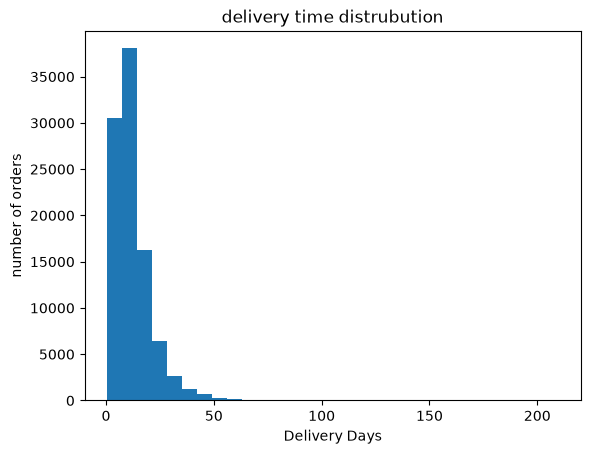

In [259]:
#histogram
plt.hist(df["delivery_days"],bins=30)
plt.xlabel("Delivery Days")
plt.ylabel("number of orders")
plt.title("delivery time distrubution")

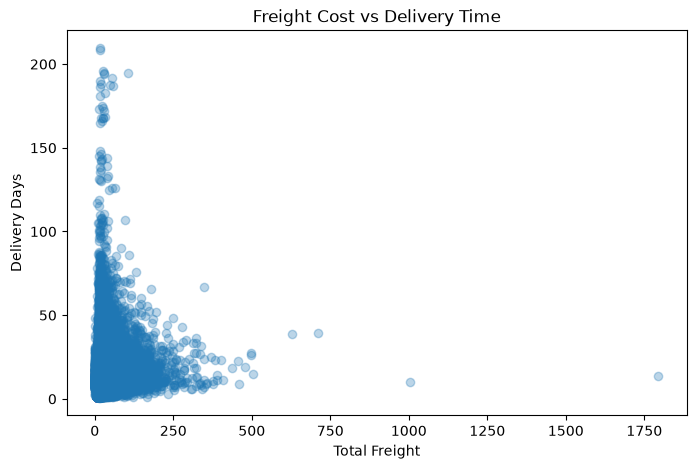

In [260]:

plt.figure(figsize=(8, 5))
plt.scatter(df["total_freight"], df["delivery_days"], alpha=0.3)
plt.xlabel("Total Freight")
plt.ylabel("Delivery Days")
plt.title("Freight Cost vs Delivery Time")
plt.show()


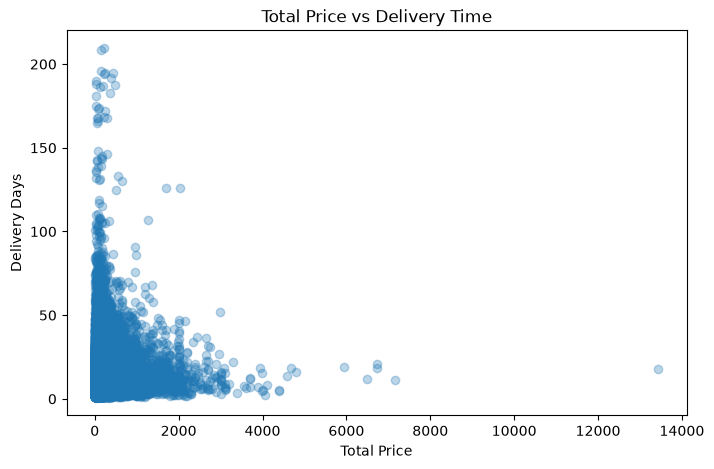

In [261]:

plt.figure(figsize=(8, 5))
plt.scatter(df["total_price"], df["delivery_days"], alpha=0.3)
plt.xlabel("Total Price")
plt.ylabel("Delivery Days")
plt.title("Total Price vs Delivery Time")
plt.show()


In [262]:
#check outliers
Q1 = df["delivery_days"].quantile(0.25)
Q3 = df["delivery_days"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1 ", Q1)
print("Q3 ", Q3)
print("IQR ", IQR)
print("Lower Bound ", lower_bound)
print("Upper Bound ", upper_bound)

Q1  6.77
Q3  15.72
IQR  8.950000000000001
Lower Bound  -6.655000000000001
Upper Bound  29.145000000000003


Before: (96470, 7)
After: (91567, 7)
Removed: 4903


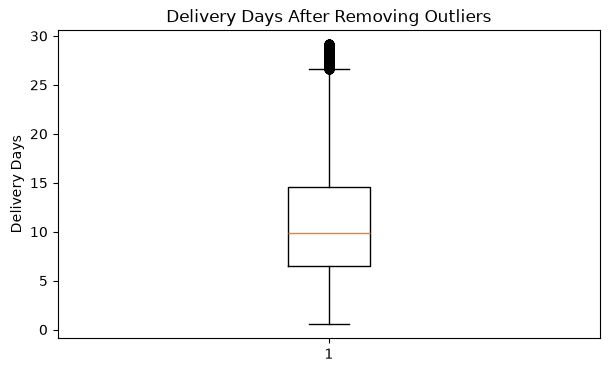

In [263]:
# Remove outliers using IQR
df_original = df.copy()

df = df[
    (df["delivery_days"] >= lower_bound) &
    (df["delivery_days"] <= upper_bound)
].copy()

print("Before:", df_original.shape)
print("After:", df.shape)
print("Removed:", len(df_original) - len(df))

plt.figure(figsize=(7, 4))
plt.boxplot(df["delivery_days"])
plt.title("Delivery Days After Removing Outliers")
plt.ylabel("Delivery Days")
plt.show()

In [265]:
# Features
X = df[
    [
        "item_count",
        "total_price",
        "total_freight",
        "customer_state",
        "unique_products",
    ]
].copy()

X = pd.get_dummies(
    X,
    columns=["customer_state"],
    dtype=int,
    drop_first=True
)

In [266]:
#Targer
Y=df["delivery_days"]

In [267]:
from sklearn.model_selection import train_test_split

In [268]:
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [269]:
from sklearn.linear_model import LinearRegression

In [270]:
model=LinearRegression()

In [271]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](30,)","[-0.41,-0. , 0.03,...,-1.07,-8.73,-1.56]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](30,)","['item_count','total_price','total_freight',...,'customer_state_SE', 'customer_state_SP','customer_state_TO']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,17.75
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,30
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(30)


In [272]:
Y_pred = model.predict(X_test)

In [273]:
print("Actual delivery days: ",Y_test.head())


print("Predicted delivery days: ",Y_pred[:5])


Actual delivery days:  29560     2.71
92307     7.05
5162     10.75
74003     8.96
71064    10.05
Name: delivery_days, dtype: float64
Predicted delivery days:  [ 8.21792843 16.18375021  8.28128398 12.19246627 12.58156958]


In [274]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [275]:
mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2=r2_score(Y_test,Y_pred)


In [276]:

print("MAE ",mae)
print("MSE ",mse)
print("RMSE ",rmse)
print("R**2 score ",r2)

MAE  4.24032391664947
MSE  29.097346198012783
RMSE  5.394195602498373
R**2 score  0.223940916822861


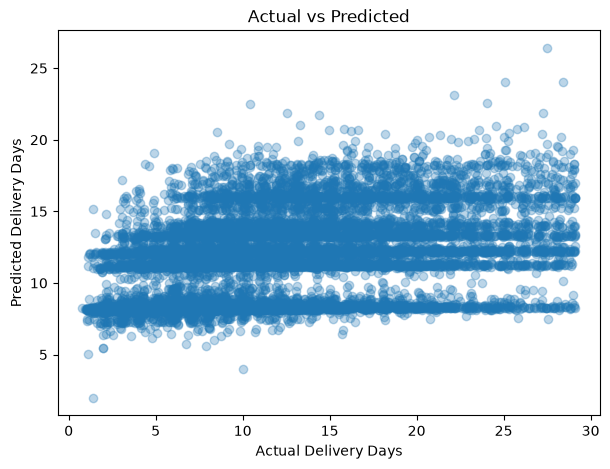

In [277]:


plt.figure(figsize=(7, 5))
plt.scatter(Y_test, Y_pred, alpha=0.3)

plt.xlabel("Actual Delivery Days")
plt.ylabel("Predicted Delivery Days")
plt.title("Actual vs Predicted")

plt.show()

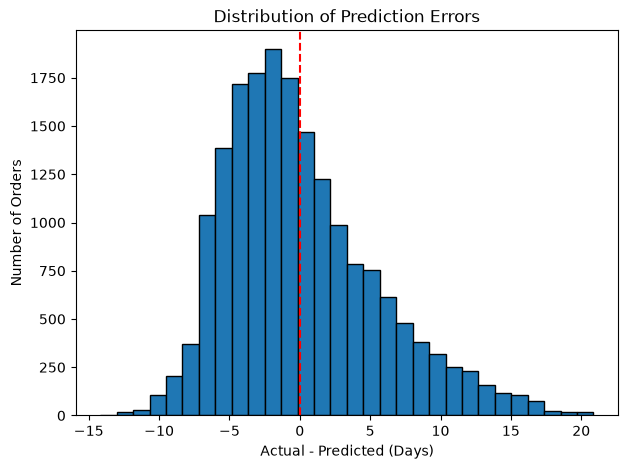

In [278]:
errors = Y_test.to_numpy() - Y_pred

plt.figure(figsize=(7, 5))
plt.hist(errors, bins=30, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")

plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual - Predicted (Days)")
plt.ylabel("Number of Orders")
plt.show()